# 01 — Exploratory data analysis (BRFSS 2015 → `_MICHD`)

**Goal:** understand the data and collect the evidence for every preprocessing decision
(implemented later in `preprocessing.py`). Numpy + matplotlib only, as required by the project rules.

**Inputs**
- `data/dataset/*.csv` (not in git, see `data/README.md`)
- `eda/special_codes.json`: per-column codebook rules (which values mean *don't know / refused* → NaN, which mean *none* → 0), built from the official
  [BRFSS 2015 codebook](https://www.cdc.gov/brfss/annual_data/annual_2015.html).
- `eda/column_decisions.csv`: one row per column with meaning, type and the recommended action.

**Outputs:** figures in `report/figures/`, and the summary of decisions at the end of the notebook (section 10).

### Summary of findings

| Topic | Finding | Consequence for preprocessing / modelling |
|---|---|---|
| Imbalance | 8.8% positives (10.3 : 1); "always −1" = 91% accuracy, F1 0 | Evaluate with F1, stratified folds, tune the threshold (≈0.2) |
| Missing values | 0 complete rows; 147 / 321 columns > 50% NaN; train ≈ test | Impute (never drop rows); drop near-empty columns |
| Informative NaN | 132 / 191 partially-missing columns change P(y) by > 0.02 when missing | Add missing indicators |
| Skip logic | e.g. BPMEDS is NaN exactly when no high blood pressure | Fill structural NaN with the logical value (no / 0) |
| Special codes | 7/9, 77/99, 88 = none, unit codes; PHYSHLTH's most common value is 88 | Per-column mapping (`eda/special_codes.json`) |
| Signal | Age, general health, blood pressure, cholesterol, stroke, diabetes, limitations | Keep ordinal effects numeric; linear models are adequate |
| Redundancy | 6 constant, 3 duplicate pairs, 42 pairs with abs(r) > 0.9 | Keep one column per group |
| Leakage | HAREHAB1 answered ⇒ 100% positive; aspirin questions | Exclude from main model, ablation row |
| Outliers | drinks / activity minutes extremely skewed | log1p + clip, then standardize |
| Shift | none (max 0.02 std) | CV ≈ test performance |

Sections: 1 Labels & imbalance · 2 Column types · 3 Missing values · 4 Special codes · 5 Relation with the label ·
6 Redundancy · 7 Leakage · 8 Distributions & outliers · 9 Train/test shift · 10 Imbalance & threshold · 11 Decisions

In [1]:
import csv
import json
import os
import sys

sys.path.append("..")  # import the project modules from the repo root

import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data
from implementations import logistic_regression, ridge_regression

DATA_PATH = "../data/dataset"
CACHE_DIR = "../data/cache"
FIG_DIR = "../report/figures"
SEED = 42
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
np.set_printoptions(suppress=True, precision=4)

## 0. Load the data

`load_csv_data` (provided `helpers.py`) parses ~320 MB of csv with `np.genfromtxt`, which takes a while.
We cache the arrays in `data/cache/raw.npz` (git-ignored) so the next runs take a few seconds.
The column names are read from the csv header, because `load_csv_data` drops them.

In [2]:
def load_data_cached(data_path=DATA_PATH, cache_dir=CACHE_DIR):
    # Load the csv files once with helpers.load_csv_data and cache them as .npz.
    cache = os.path.join(cache_dir, "raw.npz")
    if not os.path.exists(cache):
        x_tr, x_te, y_tr, id_tr, id_te = load_csv_data(data_path)
        np.savez(cache, x_train=x_tr, x_test=x_te, y_train=y_tr, train_ids=id_tr, test_ids=id_te)
    d = np.load(cache)
    return d["x_train"], d["x_test"], d["y_train"], d["train_ids"], d["test_ids"]


x_train, x_test, y_train, train_ids, test_ids = load_data_cached()
with open(os.path.join(DATA_PATH, "x_train.csv")) as f:
    cols = f.readline().strip().split(",")[1:]
ix = {c: j for j, c in enumerate(cols)}
y01 = (y_train == 1).astype(float)  # labels in {0, 1} for rates
N, D = x_train.shape

with open("../eda/special_codes.json") as f:
    SPEC = json.load(f)
with open("../eda/column_decisions.csv") as f:
    DEC = {r["name"]: r for r in csv.DictReader(f)}
ctype = np.array([DEC[c]["type"] for c in cols])

print(f"x_train {x_train.shape} | x_test {x_test.shape} | y_train {y_train.shape} | {len(cols)} feature names")

x_train (328135, 321) | x_test (109379, 321) | y_train (328135,) | 321 feature names


## 1. Labels and class imbalance

The label `_MICHD` is a CDC calculated variable: **+1** if the person was ever told they had a heart attack (CVDINFR4)
**or** angina / coronary heart disease (CVDCRHD4). Those two source questions are **not** in the dataset.
It is a *"has ever been diagnosed"* label, so consequences of the disease (medication, poor health, limitations) are legitimately predictive.

In [3]:
p = y01.mean()
print(f"Positives: {int(y01.sum()):,} / {N:,} = {p:.2%}   ->   imbalance {(1 - p) / p:.1f} : 1")
print(f"Trivial 'always -1': accuracy {1 - p:.3f}, F1 0.000")
print(f"Trivial 'always +1': accuracy {p:.3f}, F1 {2 * p / (1 + p):.3f}")

Positives: 28,975 / 328,135 = 8.83%   ->   imbalance 10.3 : 1
Trivial 'always -1': accuracy 0.912, F1 0.000
Trivial 'always +1': accuracy 0.088, F1 0.162


**Takeaway.** Accuracy is useless here (91% by predicting nobody is sick). The AIcrowd ranking uses **F1**, so every model must be
evaluated with F1 and the decision threshold must be tuned (section 10).

## 2. Column types

All 321 columns are numeric codes. Using the codebook we classified each one (`eda/column_decisions.csv`):

In [4]:
for t, n in zip(*np.unique(ctype, return_counts=True)):
    examples = ", ".join([c for c in cols if DEC[c]["type"] == t][:6])
    print(f"{t:11s}{n:4d}   e.g. {examples}")

admin        22   e.g. FMONTH, IDATE, IMONTH, IDAY, IYEAR, DISPCODE
binary      108   e.g. LANDLINE, HLTHPLN1, MEDCOST, BPMEDS, BLOODCHO, TOLDHI2
continuous   38   e.g. DIABAGE2, WEIGHT2, HEIGHT3, EXERHMM1, EXERHMM2, ASTHMAGE
count        45   e.g. NUMADULT, NUMMEN, NUMWOMEN, HHADULT, PHYSHLTH, MENTHLTH
date          2   e.g. FLSHTMY2, HIVTSTD3
id            2   e.g. SEQNO, _PSU
nominal      47   e.g. _STATE, PERSDOC2, BPHIGH4, DIABETE3, MARITAL, RENTHOM1
ordinal      51   e.g. GENHLTH, CHECKUP1, CHOLCHK, EDUCA, INCOME2, SMOKDAY2
weight        6   e.g. _STRWT, _RAWRAKE, _WT2RAKE, _CLLCPWT, _DUALCOR, _LLCPWT


- **admin / id / date / weight (32 columns)**: interview dates, sequence numbers, phone-screening questions and survey weights.
  They describe *how* the survey was run, not the person → drop (with one exception, the landline flag, see 3.4).
- **binary** (mostly 1 = yes, 2 = no, 7 = don't know, 9 = refused) → recode to 1/0.
- **ordinal** (e.g. GENHLTH 1 = excellent … 5 = poor, income and education levels) → keep as numbers.
- **nominal** (e.g. marital status, employment, race) → one-hot encode.
- **continuous / count** (age, BMI, days of poor health, drinks per week, minutes of activity) → keep, clean codes, clip/log tails.

## 3. Missing values

### 3.1 How much is missing?

Columns with no NaN: 82
Columns with > 10% NaN: 182
Columns with > 50% NaN: 147
Columns with > 80% NaN: 116
Columns with > 90% NaN: 99
Columns with > 99% NaN: 30
Fraction of NaN per row: mean 44.8%, min 24.9%, max 67.9%
Rows without any NaN: 0
Max |NaN rate train - NaN rate test| over columns: 0.0040


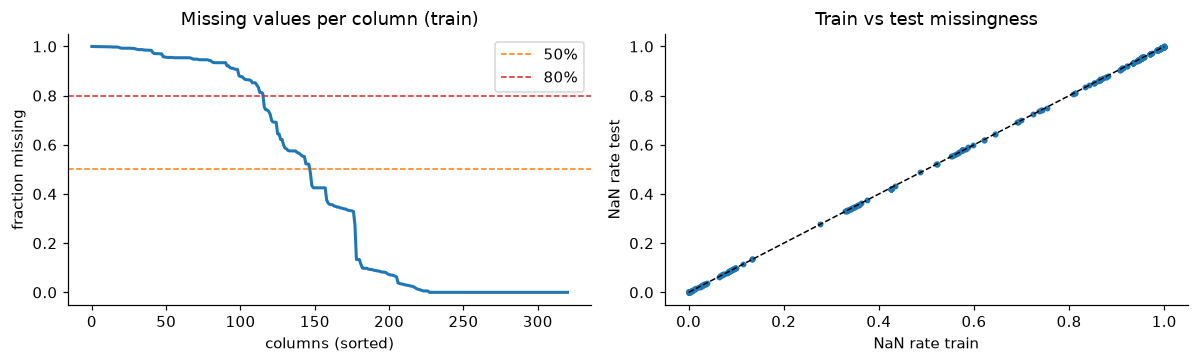

In [5]:
nan_tr = np.isnan(x_train).mean(axis=0)
nan_te = np.isnan(x_test).mean(axis=0)
row_nan = np.isnan(x_train).mean(axis=1)
print(f"Columns with no NaN: {(nan_tr == 0).sum()}")
for t in [0.1, 0.5, 0.8, 0.9, 0.99]:
    print(f"Columns with > {t:.0%} NaN: {(nan_tr > t).sum()}")
print(f"Fraction of NaN per row: mean {row_nan.mean():.1%}, min {row_nan.min():.1%}, max {row_nan.max():.1%}")
print(f"Rows without any NaN: {(row_nan == 0).sum()}")
print(f"Max |NaN rate train - NaN rate test| over columns: {np.abs(nan_tr - nan_te).max():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(np.sort(nan_tr)[::-1], lw=2)
for t, c in [(0.5, "tab:orange"), (0.8, "tab:red")]:
    ax[0].axhline(t, ls="--", c=c, lw=1, label=f"{t:.0%}")
ax[0].set(xlabel="columns (sorted)", ylabel="fraction missing", title="Missing values per column (train)")
ax[0].legend()
ax[1].scatter(nan_tr, nan_te, s=8)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlabel="NaN rate train", ylabel="NaN rate test", title="Train vs test missingness")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/missing_per_column.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- Missingness is massive: no row is complete, so **dropping rows is impossible** (and we must predict every test row anyway). We need imputation.
- Missingness is the same in train and test → whatever rule we learn on train transfers to test.
- The sorted curve has plateaus: groups of columns missing together. They come from the questionnaire structure (3.3) and from optional modules asked only in some states (3.4).

### 3.2 Is missingness informative?

If people with a missing value have a different disease rate than people who answered, *the fact of being missing is information*,
and imputing a value would erase it. We compare P(y = 1 | NaN) with P(y = 1 | observed) for every partially-missing column.

column      NaN rate  P(y=1|NaN)  P(y=1|obs)   meaning
DIABAGE2       87.1%       0.069       0.221   How old were you when you were told you have diabetes?
CDDISCUS       97.1%       0.084       0.227   Have you or anyone else discussed your confusion or mem
CDSOCIAL       97.1%       0.084       0.227   During the past 12 months; how often has confusion or m
CDASSIST       97.1%       0.084       0.227   As a result of confusion or memory loss; how often do y
CDHOUSE        97.1%       0.084       0.227   During the past 12 months; as a result of confusion or 
BLDSUGAR       93.4%       0.079       0.219   About how often do you check your blood for glucose or 
DIABEYE        93.4%       0.079       0.219   Has a doctor ever told you that diabetes has affected y
DIABEDU        93.4%       0.079       0.219   Have you ever taken a course or class in how to manage 
INSULIN        93.4%       0.079       0.219   Are you now taking insulin?
DOCTDIAB       93.4%       0.079       0.219   

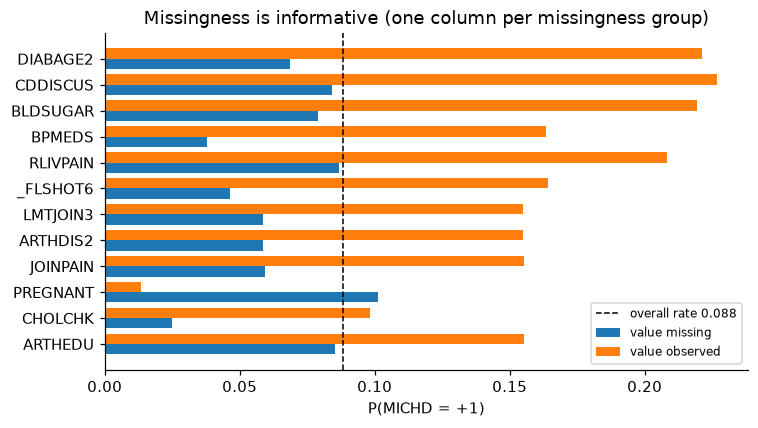

In [6]:
def pos_rate(mask):
    return y01[mask].mean() if mask.any() else np.nan


rows = []
for j, c in enumerate(cols):
    m = np.isnan(x_train[:, j])
    if 0.01 < m.mean() < 0.99:
        rows.append((c, m.mean(), pos_rate(m), pos_rate(~m)))
rows.sort(key=lambda r: -abs(r[2] - r[3]))

print(f"{'column':10s}{'NaN rate':>10s}{'P(y=1|NaN)':>12s}{'P(y=1|obs)':>12s}   meaning")
for c, r, a, b in rows[:20]:
    print(f"{c:10s}{r:10.1%}{a:12.3f}{b:12.3f}   {DEC[c]['description'][:55]}")
n_inf = sum(abs(a - b) > 0.02 for _, _, a, b in rows)
print(f"\n{n_inf} of {len(rows)} partially-missing columns: |P(y|NaN) - P(y|obs)| > 0.02")

# one column per group of columns that are missing together (same rates), for readability
seen, top = set(), []
for r in rows:
    key = (round(r[1], 3), round(r[2], 3))
    if key not in seen:
        seen.add(key)
        top.append(r)
top = top[:12][::-1]
fig, ax = plt.subplots(figsize=(7, 4))
yy = np.arange(len(top))
ax.barh(yy - 0.2, [r[2] for r in top], 0.4, label="value missing")
ax.barh(yy + 0.2, [r[3] for r in top], 0.4, label="value observed")
ax.axvline(p, c="k", ls="--", lw=1, label=f"overall rate {p:.3f}")
ax.set_yticks(yy, [r[0] for r in top])
ax.set(xlabel="P(MICHD = +1)", title="Missingness is informative (one column per missingness group)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/informative_missingness.png", bbox_inches="tight")
plt.show()

**Takeaway.** For many columns the disease rate changes a lot depending on whether the value is missing →
**add a binary "was missing" indicator** for the kept columns with informative missingness, *before* imputing.

### 3.3 Structural missingness (skip logic)

Many questions are only asked depending on a previous answer (e.g. *"do you take medication for high blood pressure?"*
is only asked to people with high blood pressure). Then NaN does not mean *unknown*: it means *"no / zero"*.
We verify each rule from the codebook on the data:

In [7]:
def skip_check(target, cond, desc):
    t = np.isnan(x_train[:, ix[target]])
    print(f"{target:9s} NaN rate  if {desc:38s}: {t[cond].mean():6.1%}   otherwise: {t[~cond].mean():6.1%}")


col = lambda c: x_train[:, ix[c]]
skip_check("BPMEDS", col("BPHIGH4") == 1, "BPHIGH4 = 1 (has high blood pressure)")
skip_check("TOLDHI2", col("BLOODCHO") == 1, "BLOODCHO = 1 (cholesterol checked)")
skip_check("SMOKDAY2", col("SMOKE100") == 1, "SMOKE100 = 1 (smoked 100 cigarettes)")
skip_check("AVEDRNK2", col("ALCDAY5") == 888, "ALCDAY5 = 888 (no drinks in 30 days)")
skip_check("POORHLTH", (col("PHYSHLTH") == 88) & (col("MENTHLTH") == 88), "PHYSHLTH = MENTHLTH = 88 (no bad days)")
skip_check("DIABAGE2", col("DIABETE3") == 1, "DIABETE3 = 1 (has diabetes)")
skip_check("JOINPAIN", col("HAVARTH3") == 1, "HAVARTH3 = 1 (has arthritis)")
skip_check("PA1MIN_", col("EXERANY2") == 2, "EXERANY2 = 2 (no exercise)")

BPMEDS    NaN rate  if BPHIGH4 = 1 (has high blood pressure) :   0.0%   otherwise: 100.0%
TOLDHI2   NaN rate  if BLOODCHO = 1 (cholesterol checked)    :   0.0%   otherwise: 100.0%
SMOKDAY2  NaN rate  if SMOKE100 = 1 (smoked 100 cigarettes)  :   0.1%   otherwise: 100.0%
AVEDRNK2  NaN rate  if ALCDAY5 = 888 (no drinks in 30 days)  : 100.0%   otherwise:   9.4%
POORHLTH  NaN rate  if PHYSHLTH = MENTHLTH = 88 (no bad days): 100.0%   otherwise:   0.0%
DIABAGE2  NaN rate  if DIABETE3 = 1 (has diabetes)           :   0.0%   otherwise: 100.0%
JOINPAIN  NaN rate  if HAVARTH3 = 1 (has arthritis)          :   9.6%   otherwise: 100.0%
PA1MIN_   NaN rate  if EXERANY2 = 2 (no exercise)            : 100.0%   otherwise:  13.4%


**Takeaway.** The NaN appears (almost) only when the question was skipped (≈0% vs ≈100%; the remaining ≈10% for AVEDRNK2 / JOINPAIN are real "don't know" answers). For these columns the NaN is **structural** and must be filled with its
logical value (*no medication*, *0 drinks*, *0 poor-health days*, *0 minutes of activity*, …), not with the median.
The full list of fills is in `eda/special_codes.json` → `_transforms.structural_zeros`.

### 3.4 Optional modules and the landline / cell-phone split

Columns with > 50% NaN: are they asked everywhere (skip logic) or only in some states (optional modules)?

147 columns with > 50% NaN, asked (>5% answered) in how many of the 53 states:
  >= 45 states (core questions with skip logic): 31
  11-44 states                                 : 39
  <= 10 states (optional state modules)        : 77
  e.g. NUMPHON2(5), VIDFCLT2(1), VIREDIF3(1), VIPRFVS2(1), VINOCRE2(1), VIEYEXM2(1), VIINSUR2(1), VICTRCT4(1), VIGLUMA2(1), VIMACDG2(1), CDHELP(0), WTCHSALT(7)

Landline interviews: 57.5% of rows -> P(y=1) = 0.107
Cell-phone interviews: 42.5% of rows -> P(y=1) = 0.062


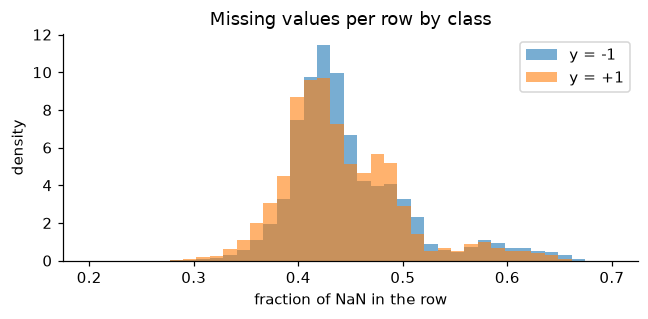

In [8]:
state = x_train[:, ix["_STATE"]]
states = np.unique(state)
high = np.where(nan_tr > 0.5)[0]
answered = np.array([(~np.isnan(x_train[state == s][:, high])).mean(axis=0) for s in states])  # (states, cols)
n_states = (answered > 0.05).sum(axis=0)
print(f"{len(high)} columns with > 50% NaN, asked (>5% answered) in how many of the {len(states)} states:")
print(f"  >= 45 states (core questions with skip logic): {(n_states >= 45).sum()}")
print(f"  11-44 states                                 : {((n_states > 10) & (n_states < 45)).sum()}")
print(f"  <= 10 states (optional state modules)        : {(n_states <= 10).sum()}")
print("  e.g.", ", ".join([f"{cols[j]}({n})" for j, n in zip(high, n_states) if n <= 10 and ctype[j] not in ("admin", "id", "date", "weight")][:12]))

land = x_train[:, ix["QSTVER"]] < 20
print(f"\nLandline interviews: {land.mean():.1%} of rows -> P(y=1) = {pos_rate(land):.3f}")
print(f"Cell-phone interviews: {(~land).mean():.1%} of rows -> P(y=1) = {pos_rate(~land):.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0.2, 0.7, 40)
ax.hist(row_nan[y01 == 0], bins, density=True, alpha=0.6, label="y = -1")
ax.hist(row_nan[y01 == 1], bins, density=True, alpha=0.6, label="y = +1")
ax.set(xlabel="fraction of NaN in the row", ylabel="density", title="Missing values per row by class")
ax.legend()
plt.tight_layout()
plt.show()

**Takeaways.**
- Most near-empty columns are **optional modules** run by a handful of states (caregiving, vision, cognitive decline, HPV, cancer screening…).
  For > 90% of people they are simply not asked, so they carry little usable information → **drop columns above a NaN threshold (≈80%)**,
  except the few that are strongly informative when present (diabetes insulin, leakage suspects of section 7).
- The landline / cell-phone block (phone-screening columns) is admin data, but the **interview type itself matters**
  (landline respondents have a much higher rate, probably because they are older on average). One flag `is_landline = QSTVER < 20` replaces the whole block.
- The number of NaN per row is almost identical in both classes → not worth a feature.

## 4. Special codes inside numeric columns

BRFSS stores *don't know / refused / none* as numbers: 7/9, 77/99, 777/999 mean *don't know / refused*, 88 / 888 mean *none* (= 0),
555 means *never*, and several columns encode units in the first digit (e.g. `ALCDAY5`: 1xx = days per week, 2xx = days per month).
If we feed them as numbers, *"refused"* (99) becomes *"99 days of poor health"*. The codes depend on the column, so the rules are per column.

column      DK/refused codes   share  P(y|code)  P(y|valid)
_CHISPNC                 [9]   58.4%      0.099       0.031
_HCVU651                 [9]   35.9%      0.163       0.046
_INCOMG                  [9]   17.9%      0.094       0.087
INCOME2             [77, 99]   17.1%      0.095       0.087
_PAREC1                  [9]   13.0%      0.087       0.088
_PASTAE1                 [9]   13.0%      0.087       0.088
_PACAT1                  [9]   12.6%      0.086       0.089
_PA300R2                 [9]   12.6%      0.086       0.089
_PA30021                 [9]   12.6%      0.086       0.089
_PAINDX1                 [9]   12.0%      0.085       0.089
_PA150R2                 [9]   12.0%      0.085       0.089
_VEGLT1                  [9]   11.5%      0.095       0.087
_PASTRNG                 [9]    9.9%      0.083       0.089
_FRTLT1                  [9]    9.8%      0.089       0.088
_RFSEAT2                 [9]    9.6%      0.083       0.089

'Don't know' (7) on health-condition qu

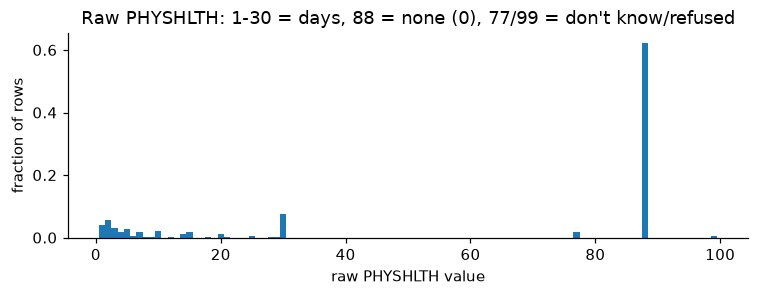

In [9]:
stats = []
for j, c in enumerate(cols):
    codes = SPEC.get(c, {}).get("nan_codes", [])
    if not codes or ctype[j] in ("admin", "id", "date", "weight"):
        continue
    v = x_train[:, j]
    m = np.isin(v, codes)
    if m.mean() >= 0.01:
        stats.append((c, codes, m.mean(), pos_rate(m), pos_rate(~m & ~np.isnan(v))))
stats.sort(key=lambda r: -r[2])
print(f"{'column':10s}{'DK/refused codes':>18s}{'share':>8s}{'P(y|code)':>11s}{'P(y|valid)':>12s}")
for c, codes, s, a, b in stats[:15]:
    print(f"{c:10s}{str(codes):>18s}{s:8.1%}{a:11.3f}{b:12.3f}")

print("\n'Don't know' (7) on health-condition questions:")
for c in ["CVDSTRK3", "CHCCOPD1", "CHCKIDNY", "TOLDHI2"]:
    v = x_train[:, ix[c]]
    print(f"  {c:9s} yes(1): {pos_rate(v == 1):.3f}   no(2): {pos_rate(v == 2):.3f}   don't know(7): {pos_rate(v == 7):.3f}")

g = x_train[:, ix["GENHLTH"]]
print(f"  GENHLTH   excellent(1): {pos_rate(g == 1):.3f}   poor(5): {pos_rate(g == 5):.3f}   don't know(7): {pos_rate(g == 7):.3f}")

v = x_train[:, ix["PHYSHLTH"]]
vals, cnt = np.unique(v[~np.isnan(v)], return_counts=True)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(vals, cnt / N, width=1.0)
ax.set(xlabel="raw PHYSHLTH value", ylabel="fraction of rows",
       title="Raw PHYSHLTH: 1-30 = days, 88 = none (0), 77/99 = don't know/refused")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/special_codes_physhlth.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- In several *calculated* columns the code 9 means *not applicable* rather than *don't know* (e.g. `_HCVU651` = 9 for everybody aged 65+,
  `_CHISPNC` = 9 for people without children) → that is why their P(y | code) is so different. The missing indicator keeps this information.
- Special codes are frequent (e.g. income *refused/don't know* ≈ 17% of rows) → mapping them is necessary, per column, from `eda/special_codes.json`.
- `88 = none` is the **most common value** of PHYSHLTH: left as is, it would be read as "88 days" → it must become **0**.
- *Don't know* is not neutral: people who don't know whether they had a stroke have a much higher disease rate → after mapping the code to NaN,
  the missing indicator keeps that signal.

## 5. Relation with the label

We first apply the codebook mapping (special codes → NaN or 0) so that the statistics are computed on real values.

In [10]:
def clean_codes(x):
    # EDA-level cleaning: per-column special codes -> NaN ('don't know/refused') or 0 ('none/never').
    x = x.copy()
    for j, c in enumerate(cols):
        s = SPEC.get(c)
        if not s:
            continue
        raw = x[:, j].copy()
        x[np.isin(raw, s["nan_codes"]), j] = np.nan
        x[np.isin(raw, s["zero_codes"]), j] = 0
    return x


xc = clean_codes(x_train)
xc_te = clean_codes(x_test)
print("cleaned arrays:", xc.shape, xc_te.shape)

cleaned arrays: (328135, 321) (109379, 321)


### 5.1 Main risk factors

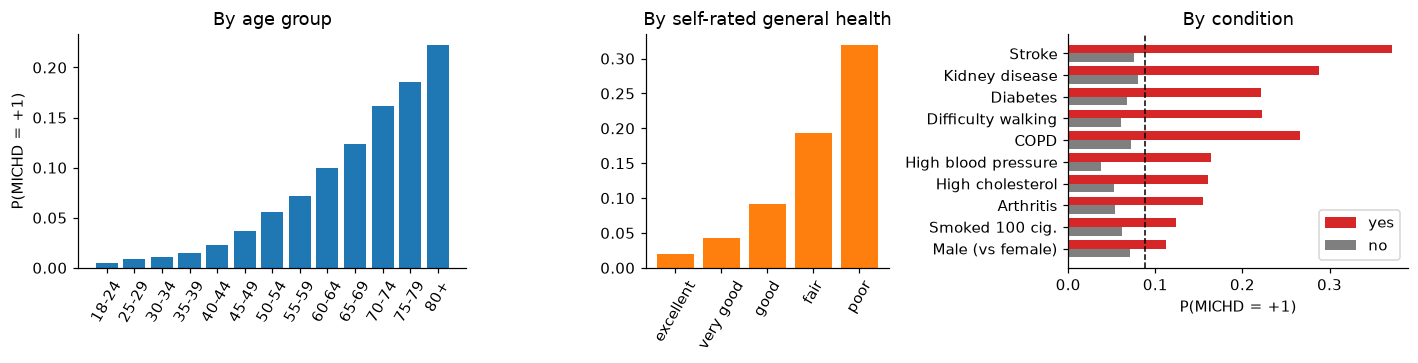

Stroke               yes 0.371  no 0.076  ratio  4.9x
Kidney disease       yes 0.288  no 0.081  ratio  3.6x
Diabetes             yes 0.221  no 0.067  ratio  3.3x
Difficulty walking   yes 0.223  no 0.060  ratio  3.7x
COPD                 yes 0.267  no 0.072  ratio  3.7x
High blood pressure  yes 0.163  no 0.037  ratio  4.4x
High cholesterol     yes 0.161  no 0.052  ratio  3.1x
Arthritis            yes 0.155  no 0.054  ratio  2.9x
Smoked 100 cig.      yes 0.124  no 0.062  ratio  2.0x
Male (vs female)     yes 0.112  no 0.071  ratio  1.6x


In [11]:
def rate_by_value(c):
    v = xc[:, ix[c]]
    m = ~np.isnan(v)
    vals, inv = np.unique(v[m], return_inverse=True)
    cnt = np.bincount(inv)
    return vals, np.bincount(inv, weights=y01[m]) / cnt, cnt


age_labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1.6, 1, 1.4]})
vals, rate, _ = rate_by_value("_AGEG5YR")
ax[0].bar(range(len(vals)), rate)
ax[0].set_xticks(range(len(vals)), age_labels[: len(vals)], rotation=60)
ax[0].set(ylabel="P(MICHD = +1)", title="By age group")
vals, rate, _ = rate_by_value("GENHLTH")
ax[1].bar(range(len(vals)), rate, color="tab:orange")
ax[1].set_xticks(range(len(vals)), ["excellent", "very good", "good", "fair", "poor"][: len(vals)], rotation=60)
ax[1].set(title="By self-rated general health")

factors = [("Stroke", "CVDSTRK3", 1, 2), ("Kidney disease", "CHCKIDNY", 1, 2), ("Diabetes", "DIABETE3", 1, 3),
           ("Difficulty walking", "DIFFWALK", 1, 2), ("COPD", "CHCCOPD1", 1, 2), ("High blood pressure", "BPHIGH4", 1, 3),
           ("High cholesterol", "TOLDHI2", 1, 2), ("Arthritis", "HAVARTH3", 1, 2), ("Smoked 100 cig.", "SMOKE100", 1, 2),
           ("Male (vs female)", "SEX", 1, 2)]
yes = [pos_rate(xc[:, ix[c]] == a) for _, c, a, b in factors]
no = [pos_rate(xc[:, ix[c]] == b) for _, c, a, b in factors]
yy = np.arange(len(factors))[::-1]
ax[2].barh(yy + 0.2, yes, 0.4, label="yes", color="tab:red")
ax[2].barh(yy - 0.2, no, 0.4, label="no", color="tab:gray")
ax[2].set_yticks(yy, [f[0] for f in factors])
ax[2].axvline(p, c="k", ls="--", lw=1)
ax[2].set(xlabel="P(MICHD = +1)", title="By condition")
ax[2].legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/risk_factors.png", bbox_inches="tight")
plt.show()
for (name, c, a, b), ry, rn in zip(factors, yes, no):
    print(f"{name:20s} yes {ry:.3f}  no {rn:.3f}  ratio {ry / rn:4.1f}x")

**Takeaways.** The classic cardiovascular risk factors show up clearly: the rate goes from ≈0.5% at 18–24 to > 20% at 80+, and from ≈2% (excellent health)
to > 30% (poor health). Stroke, kidney disease, diabetes, hypertension and high cholesterol multiply the risk by 2–5×.
- **Age and general health have a monotone effect** → keep them as ordinal / continuous numbers.
- Yes/no columns are coded 1 = yes, 2 = no; recoding them to 1/0 makes the sign of the weights readable.

### 5.2 Ranking all features

Mutual information (MI) between each column and the label, keeping **NaN as its own category** (so it also captures informative missingness),
plus the correlation computed on observed values only.

/Users/zhiqian/miniconda3/envs/ml/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/zhiqian/miniconda3/envs/ml/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


  # column      MI x1e3    corr    NaN   meaning
  1 GENHLTH        43.6   0.249     0%   Would you say that in general your health is:
  2 _AGEG5YR       43.2   0.227     0%   Fourteen-level age category
  3 _AGE80         43.0   0.225     0%   Imputed Age value collapsed above 80
  4 MAXVO2_        42.1  -0.224     0%   Estimated Age-Gender Specific Maximum Oxygen 
  5 FC60_          42.1  -0.224     0%   Estimated Functional Capacity
  6 _AGE_G         39.9   0.207     0%   Six-level imputed age category
  7 EMPLOY1        38.3   0.212     0%   Are you currently…?
  8 BPMEDS         37.0  -0.104    60%   Are you currently taking medicine for your hi
  9 BPHIGH4        33.9  -0.215     0%   Have you EVER been told by a doctor; nurse or
 10 _RFHYPE5       33.8   0.218     0%   Adults who have been told they have high bloo
 11 _RFHLTH        32.0   0.235     0%   Adults with good or better health
 12 _AGE65YR       28.0   0.204     0%   Two-level age category
 13 _HCVU651       26.8  -

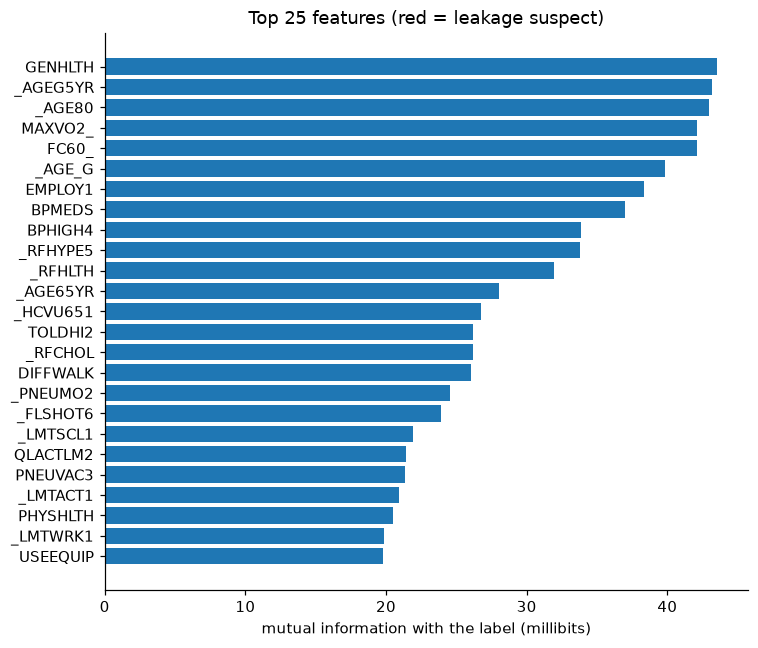


103 of 289 non-admin columns have MI < 1 millibit (almost no signal)


In [12]:
def mutual_info(v, y, max_bins=10):
    # Mutual information in bits between a feature (NaN = own category) and binary y.
    nan = np.isnan(v)
    codes = np.zeros(len(v), dtype=int)
    obs = v[~nan]
    if obs.size:
        if np.unique(obs).size > 20:
            edges = np.unique(np.quantile(obs, np.linspace(0, 1, max_bins + 1)[1:-1]))
            codes[~nan] = np.digitize(obs, edges)
        else:
            codes[~nan] = np.unique(obs, return_inverse=True)[1]
    codes[nan] = codes.max() + 1
    joint = np.bincount(codes * 2 + y.astype(int), minlength=2 * (codes.max() + 1)).reshape(-1, 2) / len(v)
    px, py = joint.sum(1, keepdims=True), joint.sum(0, keepdims=True)
    nz = joint > 0
    return float((joint[nz] * np.log2(joint[nz] / (px @ py)[nz])).sum())


def corr_obs(v, y):
    m = ~np.isnan(v)
    if m.sum() < 100 or np.std(v[m]) == 0:
        return 0.0
    return float(np.corrcoef(v[m], y[m])[0, 1])


skip_types = ("admin", "id", "date", "weight")
rank = []
for j, c in enumerate(cols):
    if ctype[j] in skip_types:
        continue
    rank.append((c, 1000 * mutual_info(xc[:, j], y01), corr_obs(xc[:, j], y01), nan_tr[j]))
rank.sort(key=lambda r: -r[1])
leak = {"HAREHAB1", "CVDASPRN", "RDUCHART", "RDUCSTRK", "ASPUNSAF", "RLIVPAIN"}  # see section 7

print(f"{'#':>3s} {'column':10s}{'MI x1e3':>9s}{'corr':>8s}{'NaN':>7s}   meaning")
for k, (c, mi, r, nr) in enumerate(rank[:30], 1):
    flag = "  <- LEAKAGE?" if c in leak else ""
    print(f"{k:3d} {c:10s}{mi:9.1f}{r:8.3f}{nr:7.0%}   {DEC[c]['description'][:45]}{flag}")

top = rank[:25][::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(range(len(top)), [r[1] for r in top], color=["tab:red" if r[0] in leak else "tab:blue" for r in top])
ax.set_yticks(range(len(top)), [r[0] for r in top])
ax.set(xlabel="mutual information with the label (millibits)", title="Top 25 features (red = leakage suspect)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/feature_ranking.png", bbox_inches="tight")
plt.show()

weak = [c for c, mi, _, _ in rank if mi < 1]
print(f"\n{len(weak)} of {len(rank)} non-admin columns have MI < 1 millibit (almost no signal)")

**Takeaways.**
- The signal is spread over many medium-strength features (general health, age, employment = retired / unable to work, blood pressure,
  cholesterol, walking difficulty, activity limitations, stroke, diabetes, arthritis, COPD…). No single feature is enough → a linear model on many cleaned features.
- Diet, alcohol and BMI are weak.
- Many columns carry almost no information → candidates to drop (especially if mostly missing).

## 6. Redundancy

Several *calculated* columns (prefix `_`) are recodes of raw answers (e.g. `_AGEG5YR`, `_AGE_G`, `_AGE65YR` vs `_AGE80`; `_RFHYPE5` vs `BPHIGH4`).
Duplicates add nothing, make XᵀX singular for `least_squares`, and dilute regularization.

Constant / empty columns: ['CTELENUM', 'COLGHOUS', 'STATERES', 'CTELNUM1', 'CELLFON2', 'CCLGHOUS']


Exact duplicate columns: [['SEQNO', '_PSU'], ['CTELNUM1', 'CELLFON2'], ['_CRACE1', '_CPRACE']]

42 pairs with |corr| > 0.9 among 153 columns with < 50% NaN, e.g.:
  TOLDHI2    ~ _RFCHOL    |r| = 1.000
  HAVARTH3   ~ _DRDXAR1   |r| = 1.000
  EXERANY2   ~ _TOTINDA   |r| = 1.000
  ASTHMA3    ~ _LTASTH1   |r| = 1.000
  HIVTST6    ~ _AIDTST3   |r| = 1.000
  MAXVO2_    ~ FC60_      |r| = 1.000
  _VEGRESP   ~ _VEGETEX   |r| = 0.998
  _FRTRESP   ~ _FRUITEX   |r| = 0.997
  HTIN4      ~ HTM4       |r| = 0.996
  _AGEG5YR   ~ _AGE80     |r| = 0.995
  CHILDREN   ~ _CHLDCNT   |r| = 0.993
  EXERHMM1   ~ PADUR1_    |r| = 0.993
  BPHIGH4    ~ _RFHYPE5   |r| = 0.991
  _RACE      ~ _RACEGR3   |r| = 0.989
  EDUCA      ~ _EDUCAG    |r| = 0.988
  INCOME2    ~ _INCOMG    |r| = 0.977
  _AGE80     ~ _AGE_G     |r| = 0.971
  _AGE80     ~ FC60_      |r| = 0.969
  _AGE80     ~ MAXVO2_    |r| = 0.969
  _AGEG5YR   ~ _AGE_G     |r| = 0.968


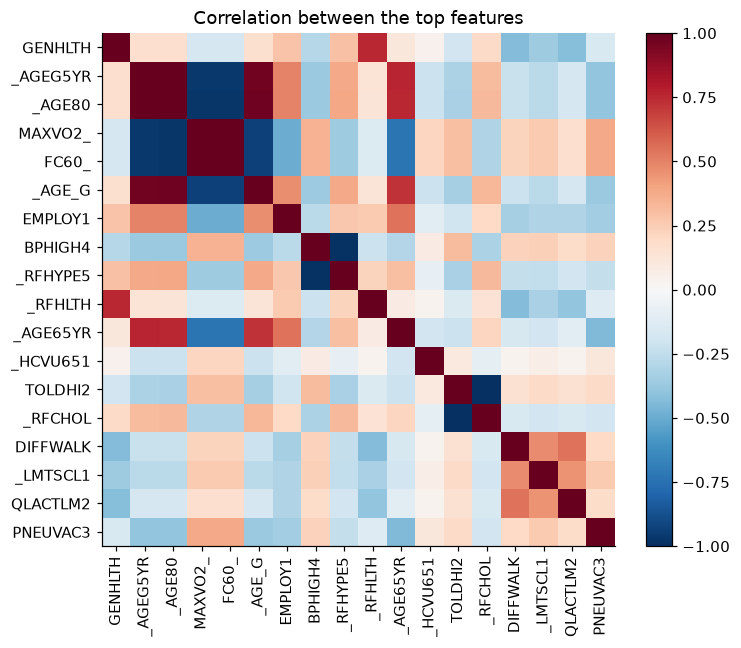

In [13]:
const = [c for j, c in enumerate(cols) if np.all(np.isnan(x_train[:, j])) or np.nanstd(x_train[:, j]) == 0]
print("Constant / empty columns:", const)

filled = np.nan_to_num(x_train, nan=-1e9)
groups = {}
for j, c in enumerate(cols):
    groups.setdefault(filled[:, j].tobytes(), []).append(c)
print("Exact duplicate columns:", [g for g in groups.values() if len(g) > 1])
del filled

rng = np.random.default_rng(SEED)
sub = rng.choice(N, 50_000, replace=False)
cand = [j for j, c in enumerate(cols) if ctype[j] not in skip_types and nan_tr[j] < 0.5 and c not in const]
xs = xc[sub][:, cand]
med = np.nanmedian(xs, axis=0)
xs = np.where(np.isnan(xs), med, xs)
keep = xs.std(axis=0) > 0
xs, cand = xs[:, keep], [j for j, k in zip(cand, keep) if k]
C = np.corrcoef(xs, rowvar=False)
iu = np.triu_indices_from(C, k=1)
pairs = sorted([(abs(C[a, b]), cols[cand[a]], cols[cand[b]]) for a, b in zip(*iu) if abs(C[a, b]) > 0.9], reverse=True)
print(f"\n{len(pairs)} pairs with |corr| > 0.9 among {len(cand)} columns with < 50% NaN, e.g.:")
for r, a, b in pairs[:20]:
    print(f"  {a:10s} ~ {b:10s} |r| = {r:.3f}")

topf = [c for c, *_ in rank if c not in leak and nan_tr[ix[c]] < 0.5][:18]
M = np.array([xc[sub, ix[c]] for c in topf]).T
M = np.where(np.isnan(M), np.nanmedian(M, axis=0), M)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.corrcoef(M, rowvar=False), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(topf)), topf, rotation=90)
ax.set_yticks(range(len(topf)), topf)
ax.set_title("Correlation between the top features")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_top_features.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- Drop constant columns and exact duplicates.
- For every redundant group keep **one** version, preferring the cleaner calculated one (e.g. `_AGE80` for age, `WTKG3`/`_BMI5` instead of the
  mixed-unit `WEIGHT2`/`HEIGHT3`, `DROCDY3_` instead of `ALCDAY5`).
- Remaining correlations among the top features are moderate (health / limitation questions) → ridge / regularized logistic regression handle them.

## 7. Leakage suspects

Some questions are only asked to people who already had the disease, or are a consequence of it.

In [14]:
h = x_train[:, ix["HAREHAB1"]]
ans = ~np.isnan(h)
print(f"HAREHAB1 (cardiac rehabilitation after a heart attack): answered by {ans.sum()} train rows "
      f"({(~np.isnan(x_test[:, ix['HAREHAB1']])).sum()} test rows) -> P(y=1 | answered) = {pos_rate(ans):.3f}")
print("\nAspirin questions (cardiovascular module, a few states):")
for c in ["CVDASPRN", "RDUCHART", "RDUCSTRK", "ASPUNSAF", "RLIVPAIN"]:
    v = xc[:, ix[c]]
    print(f"  {c:9s} answered {(~np.isnan(v)).mean():5.1%}   yes: {pos_rate(v == 1):.3f}   no: {pos_rate(v == 2):.3f}   "
          f"| {DEC[c]['description'][:45]}")

HAREHAB1 (cardiac rehabilitation after a heart attack): answered by 773 train rows (238 test rows) -> P(y=1 | answered) = 1.000

Aspirin questions (cardiovascular module, a few states):
  CVDASPRN  answered  4.3%   yes: 0.208   no: 0.045   | Do you take aspirin daily or every other day?
  RDUCHART  answered  1.2%   yes: 0.234   no: 0.066   | Do you take aspirin to reduce the chance of a
  RDUCSTRK  answered  1.2%   yes: 0.223   no: 0.172   | Do you take aspirin to reduce the chance of a
  ASPUNSAF  answered  3.0%   yes: 0.144   no: 0.120   | Do you have a health problem or condition tha
  RLIVPAIN  answered  1.3%   yes: 0.151   no: 0.224   | Do you take aspirin to relieve pain?


**Takeaways.**
- `HAREHAB1` is a **near copy of the label**: whoever answered it had a heart attack (100% positive). It is also present in the test set,
  so it would raise the score for ≈240 test rows, but it is not a genuine predictor.
- The aspirin questions are *reverse causation*: people take aspirin **because** they have heart disease.
- **Decision:** exclude them from the main model (clean model) and report their effect in a separate ablation row, so the choice is transparent in the report.

## 8. Distributions and outliers of continuous features

column          min       p1   median       p99        max   skew
_AGE80         18.0     19.0     58.0      80.0       80.0   -0.4
_BMI5          12.0     17.9     26.9      49.4       97.7    2.3
WTKG3          22.7     46.3     77.6     145.2      289.9    1.7
HTIN4          36.0     59.0     66.0      76.0       95.0    0.2
PHYSHLTH        0.0      0.0      0.0      30.0       30.0    2.2
MENTHLTH        0.0      0.0      0.0      30.0       30.0    2.6
POORHLTH        0.0      0.0      0.0      30.0       30.0    1.8
CHILDREN        0.0      0.0      0.0       4.0       77.0    4.1
_DRNKWEK        0.0      0.0     23.0    2800.0    53200.0   18.0
DROCDY3_        0.0      0.0      3.0     100.0      100.0    2.0
AVEDRNK2        1.0      1.0      2.0      10.0       76.0    8.6
MAXDRNKS        1.0      1.0      2.0      15.0       76.0    4.8
PA1MIN_         0.0      0.0    270.0    3495.0    54000.0   10.8
PA1VIGM_        0.0      0.0      0.0    1440.0    19200.0    9.1
STRFREQ_  

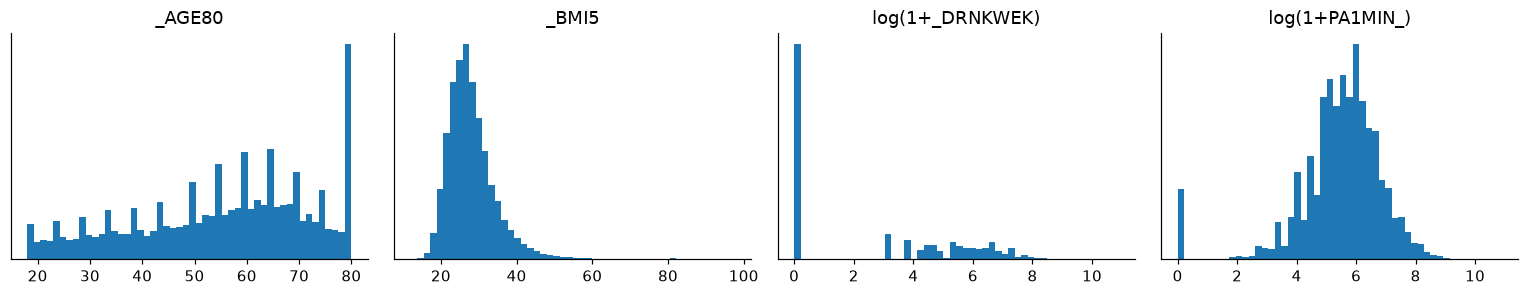

In [15]:
cont = [c for c in ["_AGE80", "_BMI5", "WTKG3", "HTIN4", "PHYSHLTH", "MENTHLTH", "POORHLTH", "CHILDREN", "_DRNKWEK",
                    "DROCDY3_", "AVEDRNK2", "MAXDRNKS", "PA1MIN_", "PA1VIGM_", "STRFREQ_", "_FRUTSUM", "_VEGESUM"] if c in ix]
print(f"{'column':10s}{'min':>9s}{'p1':>9s}{'median':>9s}{'p99':>10s}{'max':>11s}{'skew':>7s}")
for c in cont:
    v = xc[:, ix[c]]
    v = v[~np.isnan(v)]
    q = np.percentile(v, [0, 1, 50, 99, 100])
    skew = np.mean(((v - v.mean()) / (v.std() + 1e-12)) ** 3)
    print(f"{c:10s}{q[0]:9.1f}{q[1]:9.1f}{q[2]:9.1f}{q[3]:10.1f}{q[4]:11.1f}{skew:7.1f}")

fig, ax = plt.subplots(1, 4, figsize=(14, 2.8))
for a, c, logx in zip(ax, ["_AGE80", "_BMI5", "_DRNKWEK", "PA1MIN_"], [False, False, True, True]):
    v = xc[:, ix[c]]
    v = v[~np.isnan(v)]
    a.hist(np.log1p(v) if logx else v, bins=50)
    a.set(title=f"{'log(1+' + c + ')' if logx else c}", yticks=[])
plt.tight_layout()
plt.show()

**Takeaways.**
- Age and BMI are well behaved.
- Counts such as drinks per week and minutes of activity are **heavily right-skewed** with extreme maxima → apply `log1p` and/or clip at the
  train 1st / 99th percentile; otherwise a few extreme values dominate the standardization and the gradient.
- After cleaning, every feature must be **standardized** (train mean / std), because GD uses a single step size γ for all weights.

## 9. Train / test shift

In [16]:
mu_tr, mu_te = np.nanmean(xc, axis=0), np.nanmean(xc_te, axis=0)
sd_tr = np.nanstd(xc, axis=0)
useful = np.array([t not in skip_types for t in ctype]) & (nan_tr < 0.9)
ok = (sd_tr > 0) & useful
smd = np.abs(mu_tr - mu_te)[ok] / sd_tr[ok]
names = np.array(cols)[ok]
o = np.argsort(-smd)[:5]
print(f"{ok.sum()} non-admin columns with < 90% NaN")
print("Largest standardized mean differences |mean_train - mean_test| / std:", ", ".join(f"{n} {s:.3f}" for n, s in zip(names[o], smd[o])))
print(f"Columns with difference > 0.05 std: {(smd > 0.05).sum()}")

193 non-admin columns with < 90% NaN
Largest standardized mean differences |mean_train - mean_test| / std: STOPSMK2 0.022, BLDSTOOL 0.017, CASTHDX2 0.012, _CHISPNC 0.011, WHRTST10 0.011
Columns with difference > 0.05 std: 0


**Takeaway.** No shift: the largest difference is ≈0.02 std and no column exceeds 0.05 std (near-empty columns, whose means rest on a handful of rows, are excluded).
Train and test are a random split, so cross-validation on train is a reliable estimate of the test F1.

## 10. Imbalance: why the threshold matters

Quick illustration (not the final model): 15 strong, non-redundant risk factors, median imputation, standardization, 80/20 stratified split.
We train ridge regression on ±1 labels and logistic regression (both from `implementations.py`) and look at F1 as a function of the decision threshold.

Features: ['GENHLTH', '_AGE80', 'SEX', 'BPHIGH4', 'TOLDHI2', 'DIFFWALK', 'CVDSTRK3', 'DIABETE3', 'CHCKIDNY', 'CHCCOPD1', 'HAVARTH3', 'QLACTLM2', 'PHYSHLTH', 'SMOKE100', '_BMI5']
Ridge   : F1 at threshold 0   = 0.062 | best F1 = 0.399 at -0.60
Logistic: F1 at threshold 0.5 = 0.217 | best F1 = 0.421 at 0.20  (theory: optimum ~ F1*/2 = 0.21)


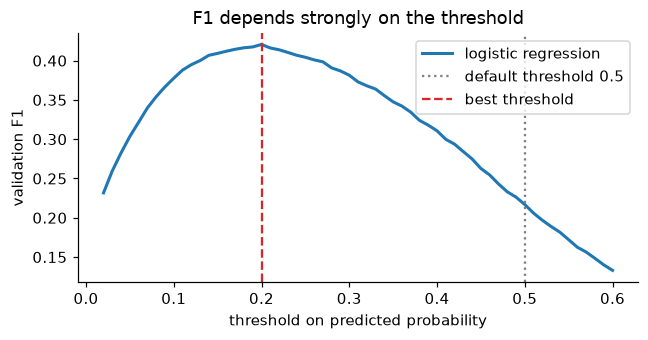

In [17]:
def f1_score(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == -1))
    fn = np.sum((y_pred == -1) & (y_true == 1))
    return 0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn)


feat = ["GENHLTH", "_AGE80", "SEX", "BPHIGH4", "TOLDHI2", "DIFFWALK", "CVDSTRK3", "DIABETE3", "CHCKIDNY",
        "CHCCOPD1", "HAVARTH3", "QLACTLM2", "PHYSHLTH", "SMOKE100", "_BMI5"]  # strong, non-redundant risk factors
X = xc[:, [ix[c] for c in feat]]
rng = np.random.default_rng(SEED)
pos, neg = np.where(y_train == 1)[0], np.where(y_train == -1)[0]
te = np.concatenate([rng.choice(pos, len(pos) // 5, replace=False), rng.choice(neg, len(neg) // 5, replace=False)])
tr = np.setdiff1d(np.arange(N), te)
med = np.nanmedian(X[tr], axis=0)
X = np.where(np.isnan(X), med, X)
mu, sd = X[tr].mean(axis=0), X[tr].std(axis=0)
tx = np.c_[np.ones(N), (X - mu) / sd]

w_r, _ = ridge_regression(y_train[tr], tx[tr], 1e-4)
w_l, _ = logistic_regression(y01[tr], tx[tr], np.zeros(tx.shape[1]), 300, 0.5)
s_r = tx[te] @ w_r
s_l = 1 / (1 + np.exp(-(tx[te] @ w_l)))

th_r = np.linspace(-1, 0.5, 61)
th_l = np.linspace(0.02, 0.6, 59)
f_r = [f1_score(y_train[te], np.where(s_r >= t, 1, -1)) for t in th_r]
f_l = [f1_score(y_train[te], np.where(s_l >= t, 1, -1)) for t in th_l]
print("Features:", feat)
print(f"Ridge   : F1 at threshold 0   = {f1_score(y_train[te], np.where(s_r >= 0, 1, -1)):.3f} | "
      f"best F1 = {max(f_r):.3f} at {th_r[int(np.argmax(f_r))]:.2f}")
print(f"Logistic: F1 at threshold 0.5 = {f1_score(y_train[te], np.where(s_l >= 0.5, 1, -1)):.3f} | "
      f"best F1 = {max(f_l):.3f} at {th_l[int(np.argmax(f_l))]:.2f}  (theory: optimum ~ F1*/2 = {max(f_l) / 2:.2f})")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(th_l, f_l, lw=2, label="logistic regression")
ax.axvline(0.5, c="gray", ls=":", label="default threshold 0.5")
ax.axvline(th_l[int(np.argmax(f_l))], c="tab:red", ls="--", label="best threshold")
ax.set(xlabel="threshold on predicted probability", ylabel="validation F1", title="F1 depends strongly on the threshold")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/f1_vs_threshold.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- With the default threshold (0.5 for probabilities, 0 for ±1 regression scores) the models predict almost no positives → very low F1.
- Tuning the threshold roughly **doubles F1 for logistic regression (0.22 → 0.42)** and is indispensable for ridge on ±1 labels (0.06 → 0.40).
- The best threshold (≈0.20) matches the theory: optimum ≈ F1*/2 (Lipton et al., 2014).
- Even this small 15-feature model reaches F1 ≈ 0.42 on validation; previous editions report ≈0.43–0.45 on AIcrowd with full pipelines.
- **Decisions:** (1) tune the threshold by cross-validation, on training folds only; (2) also try class weights / undersampling and keep them
  only if they improve CV F1 on top of the tuned threshold; (3) use **stratified** folds so every fold keeps ≈8.8% positives.

## 11. Decisions for `preprocessing.py`

| # | Step | Decision | Evidence |
|---|---|---|---|
| 1 | Admin columns | Drop ids, dates, sequence numbers, phone screeners, survey weights; keep only `is_landline = QSTVER < 20` | §2, §3.4 |
| 2 | Leakage | Exclude `HAREHAB1` and the aspirin questions (`CVDASPRN`, `RDUCHART`, `RDUCSTRK`, `ASPUNSAF`, `RLIVPAIN`) from the main model; ablation row with them | §7 |
| 3 | Special codes | Per column from `eda/special_codes.json`: don't know / refused → NaN, none / never → 0, unit codes converted (`_transforms`) | §4 |
| 4 | Structural NaN | Fill skip-logic NaN with the logical value (BPMEDS = no, drinks = 0, POORHLTH = 0, PA minutes = 0, …) | §3.3 |
| 5 | Drop columns | Constant, exact duplicates, redundant recodes (keep one per group), > 80% NaN unless informative (threshold tuned by CV) | §3.4, §6 |
| 6 | Missing indicators | Add a 0/1 "was missing" column for kept columns where P(y\|NaN) differs from P(y\|obs) | §3.2, §4 |
| 7 | Imputation | Median (numeric / ordinal) or mode (nominal), computed on the training data / folds only | §3.1 |
| 8 | Encoding | Yes/no → 1/0; ordinal kept numeric; nominal → one-hot (drop one level if using `least_squares`) | §2, §5 |
| 9 | Tails | `log1p` for skewed counts, clip at train 1st/99th percentile | §8 |
| 10 | Scaling | Standardize with train mean / std, then add the bias column | §8 |
| 11 | Imbalance | Stratified k-fold CV, tune the decision threshold for F1; try class weights / undersampling | §1, §10 |
| 12 | Validation | Train and test have the same distribution → CV F1 is a reliable proxy for AIcrowd | §3.1, §9 |

The per-column version of this table (type, NaN rate, codes, positive rates, MI, redundancy, recommended action) is `eda/column_decisions.csv`.